Stage 6 — Imbalanced Learning

Your current benchmark is:

XGBoost
PR-AUC = 0.8085
Recall  = 72.92%
Precision = 100%

Now we test whether explicitly handling the extreme imbalance improves the model.

Important: validation and test data remain completely untouched. We modify training data only.

ORIGINAL TRAINING DISTRIBUTION
Class
0    226602
1       378
Name: count, dtype: int64

Fraud rate: 0.1665%

MODEL 1 — BASELINE XGBOOST

CLASS WEIGHT
Genuine: 226602
Fraud: 378

scale_pos_weight = 599.48

MODEL 2 — XGBOOST + SCALE_POS_WEIGHT

RANDOM OVERSAMPLING
Before oversampling:
Class
0    226602
1       378
Name: count, dtype: int64

After oversampling:
Class
0    226602
1    226602
Name: count, dtype: int64

MODEL 3 — RANDOM OVERSAMPLING + XGBOOST

SMOTE
Before SMOTE:
Class
0    226602
1       378
Name: count, dtype: int64

After SMOTE:
Class
0    226602
1    226602
Name: count, dtype: int64

SMOTE training shape: (453204, 31)

MODEL 4 — SMOTE + XGBOOST

STAGE 6 — FINAL COMPARISON


,Model,Threshold,TP,FP,FN,TN,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Baseline XGBoost,0.5,35,0,13,28325,1.000000,0.729167,0.843373,0.965666,0.808477
1,XGBoost + Class Weight,0.5,36,4,12,28321,0.900000,0.750000,0.818182,0.972927,0.800328
2,Random Oversampling + XGBoost,0.5,36,5,12,28320,0.878049,0.750000,0.808989,0.972329,0.795582
3,SMOTE + XGBoost,0.5,37,5,11,28320,0.880952,0.770833,0.822222,0.958307,0.788682


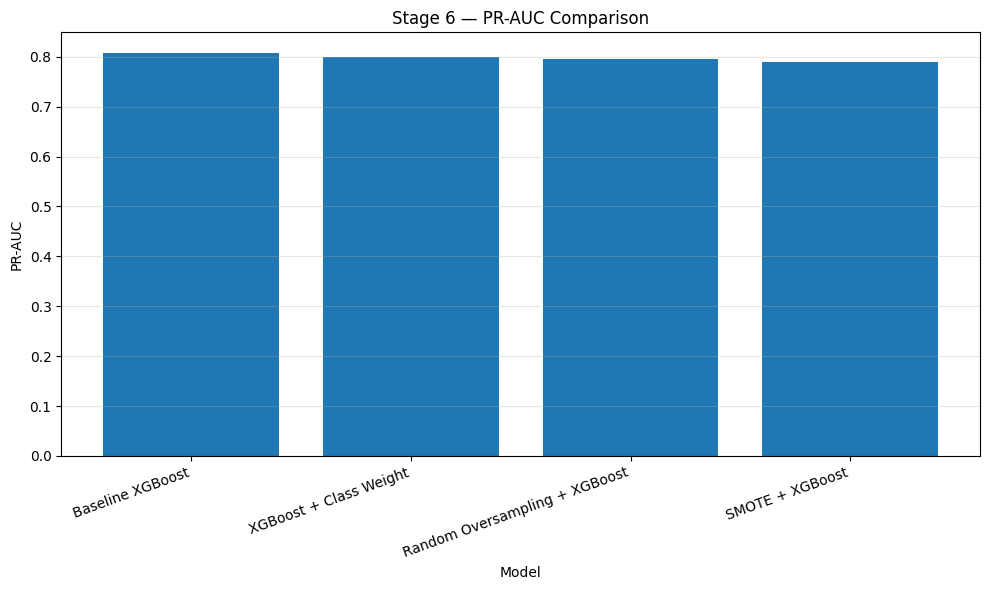

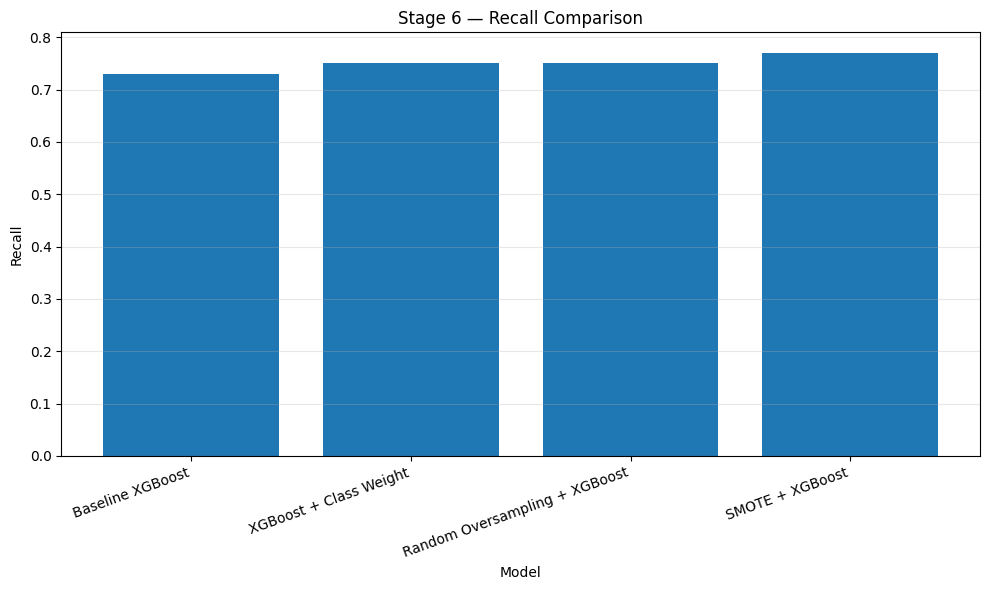

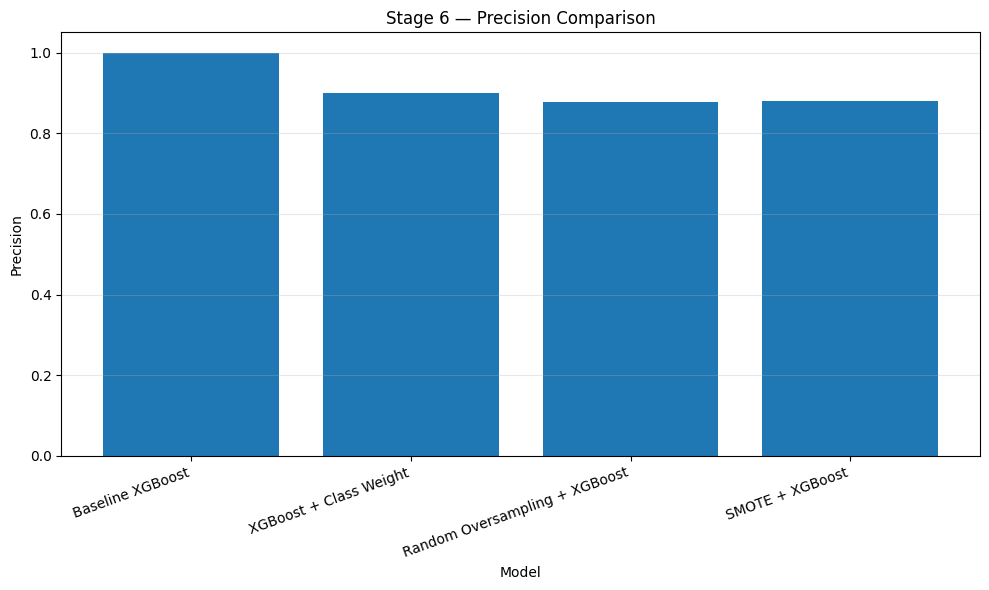


CURRENT BEST MODEL BY PR-AUC
Model     : Baseline XGBoost
PR-AUC    : 0.808477
Precision : 1.000000
Recall    : 0.729167
F1        : 0.843373
ROC-AUC   : 0.965666

LEAKAGE CHECK

Validation data was NEVER oversampled.
Validation data was NEVER used to fit SMOTE.
Validation data was NEVER used to calculate class weights.
All imbalance techniques were applied ONLY to the training set.



In [85]:
# ============================================================
# STAGE 6 — IMBALANCED LEARNING
# Credit Card Fraud Detection
# ============================================================

# ------------------------------------------------------------
# 0. INSTALL DEPENDENCIES
# ------------------------------------------------------------

!pip install -q imbalanced-learn xgboost


# ------------------------------------------------------------
# 1. IMPORTS
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

from imblearn.over_sampling import RandomOverSampler, SMOTE


# ------------------------------------------------------------
# 2. CHECK ORIGINAL TRAINING DISTRIBUTION
# ------------------------------------------------------------

print("=" * 70)
print("ORIGINAL TRAINING DISTRIBUTION")
print("=" * 70)

print(y_train.value_counts())
print()

print(
    f"Fraud rate: {y_train.mean() * 100:.4f}%"
)


# ------------------------------------------------------------
# 3. BASELINE XGBOOST
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL 1 — BASELINE XGBOOST")
print("=" * 70)

xgb_baseline = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

xgb_baseline.fit(
    X_train,
    y_train
)

baseline_proba = xgb_baseline.predict_proba(X_val)[:, 1]
baseline_pred = (baseline_proba >= 0.5).astype(int)


# ------------------------------------------------------------
# 4. CALCULATE BASELINE METRICS
# ------------------------------------------------------------

results = []

def evaluate_model(name, y_true, y_proba, threshold=0.5):

    y_pred = (y_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_true,
        y_proba
    )

    pr_auc = average_precision_score(
        y_true,
        y_proba
    )

    results.append({
        "Model": name,
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    })


evaluate_model(
    "Baseline XGBoost",
    y_val,
    baseline_proba
)


# ------------------------------------------------------------
# 5. CALCULATE SCALE_POS_WEIGHT
# ------------------------------------------------------------

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("\n" + "=" * 70)
print("CLASS WEIGHT")
print("=" * 70)

print("Genuine:", negative_count)
print("Fraud:", positive_count)

print(
    f"\nscale_pos_weight = {scale_pos_weight:.2f}"
)


# ------------------------------------------------------------
# 6. XGBOOST + CLASS WEIGHT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL 2 — XGBOOST + SCALE_POS_WEIGHT")
print("=" * 70)

xgb_weighted = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,

    scale_pos_weight=scale_pos_weight,

    objective="binary:logistic",
    eval_metric="aucpr",

    random_state=42,
    n_jobs=-1
)

xgb_weighted.fit(
    X_train,
    y_train
)

weighted_proba = xgb_weighted.predict_proba(
    X_val
)[:, 1]

weighted_pred = (
    weighted_proba >= 0.5
).astype(int)

evaluate_model(
    "XGBoost + Class Weight",
    y_val,
    weighted_proba
)


# ------------------------------------------------------------
# 7. RANDOM OVERSAMPLING
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RANDOM OVERSAMPLING")
print("=" * 70)

ros = RandomOverSampler(
    sampling_strategy=1.0,
    random_state=42
)

X_train_ros, y_train_ros = ros.fit_resample(
    X_train,
    y_train
)

print("Before oversampling:")
print(y_train.value_counts())

print("\nAfter oversampling:")
print(y_train_ros.value_counts())


# ------------------------------------------------------------
# 8. XGBOOST + RANDOM OVERSAMPLING
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL 3 — RANDOM OVERSAMPLING + XGBOOST")
print("=" * 70)

xgb_ros = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,

    objective="binary:logistic",
    eval_metric="aucpr",

    random_state=42,
    n_jobs=-1
)

xgb_ros.fit(
    X_train_ros,
    y_train_ros
)

ros_proba = xgb_ros.predict_proba(
    X_val
)[:, 1]

ros_pred = (
    ros_proba >= 0.5
).astype(int)

evaluate_model(
    "Random Oversampling + XGBoost",
    y_val,
    ros_proba
)


# ------------------------------------------------------------
# 9. SMOTE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SMOTE")
print("=" * 70)

smote = SMOTE(
    sampling_strategy=1.0,
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print(
    "\nSMOTE training shape:",
    X_train_smote.shape
)


# ------------------------------------------------------------
# 10. XGBOOST + SMOTE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL 4 — SMOTE + XGBOOST")
print("=" * 70)

xgb_smote = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,

    objective="binary:logistic",
    eval_metric="aucpr",

    random_state=42,
    n_jobs=-1
)

xgb_smote.fit(
    X_train_smote,
    y_train_smote
)

smote_proba = xgb_smote.predict_proba(
    X_val
)[:, 1]

smote_pred = (
    smote_proba >= 0.5
).astype(int)

evaluate_model(
    "SMOTE + XGBoost",
    y_val,
    smote_proba
)


# ------------------------------------------------------------
# 11. FINAL COMPARISON
# ------------------------------------------------------------

comparison_stage6 = pd.DataFrame(results)

comparison_stage6 = comparison_stage6.sort_values(
    "PR-AUC",
    ascending=False
).reset_index(drop=True)


print("\n" + "=" * 70)
print("STAGE 6 — FINAL COMPARISON")
print("=" * 70)

display(
    comparison_stage6[
        [
            "Model",
            "Threshold",
            "TP",
            "FP",
            "FN",
            "TN",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
            "PR-AUC"
        ]
    ]
)


# ------------------------------------------------------------
# 12. VISUALIZE PR-AUC
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    comparison_stage6["Model"],
    comparison_stage6["PR-AUC"]
)

plt.ylabel("PR-AUC")
plt.xlabel("Model")
plt.title("Stage 6 — PR-AUC Comparison")
plt.xticks(
    rotation=20,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. VISUALIZE RECALL
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    comparison_stage6["Model"],
    comparison_stage6["Recall"]
)

plt.ylabel("Recall")
plt.xlabel("Model")
plt.title("Stage 6 — Recall Comparison")
plt.xticks(
    rotation=20,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. VISUALIZE PRECISION
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    comparison_stage6["Model"],
    comparison_stage6["Precision"]
)

plt.ylabel("Precision")
plt.xlabel("Model")
plt.title("Stage 6 — Precision Comparison")
plt.xticks(
    rotation=20,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 15. BEST MODEL BY PR-AUC
# ------------------------------------------------------------

best_stage6 = comparison_stage6.iloc[0]

print("\n" + "=" * 70)
print("CURRENT BEST MODEL BY PR-AUC")
print("=" * 70)

print(
    f"Model     : {best_stage6['Model']}"
)

print(
    f"PR-AUC    : {best_stage6['PR-AUC']:.6f}"
)

print(
    f"Precision : {best_stage6['Precision']:.6f}"
)

print(
    f"Recall    : {best_stage6['Recall']:.6f}"
)

print(
    f"F1        : {best_stage6['F1']:.6f}"
)

print(
    f"ROC-AUC   : {best_stage6['ROC-AUC']:.6f}"
)


# ------------------------------------------------------------
# 16. IMPORTANT LEAKAGE CHECK
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LEAKAGE CHECK")
print("=" * 70)

print("""
Validation data was NEVER oversampled.
Validation data was NEVER used to fit SMOTE.
Validation data was NEVER used to calculate class weights.
All imbalance techniques were applied ONLY to the training set.
""")

For your current XGBoost configuration, the unbalanced baseline gives the highest validation PR-AUC (0.8085), while SMOTE gives the highest recall (0.7708) at threshold 0.5.

What happened
Model	PR-AUC	Recall	Precision	F1
Baseline XGBoost	0.8085	72.92%	100%	0.8434
Class Weight	0.8003	75.00%	90.00%	0.8182
Random Oversampling	0.7956	75.00%	87.80%	0.8090
SMOTE	0.7887	77.08%	88.10%	0.8222
The interesting part

Class weighting increased recall:

72.92% → 75.00%

SMOTE increased it further:

72.92% → 77.08%

But they also introduced more false positives and reduced PR-AUC.

So we're seeing the fundamental tradeoff:

                         Recall ↑
                           ↑
                           │
             SMOTE ●       │
                           │
       Class Weight ●      │
                           │
Baseline ●─────────────────┼────→ Precision
                           │

And remember: these are all at threshold = 0.5.

That's why we're not going to declare one approach universally superior. Threshold selection can completely change the precision/recall tradeoff.

STAGE 7 — THRESHOLD OPTIMIZATION
Validation samples : 28373
Actual frauds      : 48
Fraud rate         : 0.1692%

BEST THRESHOLD BY F1
Threshold        0.180000
TP              36.000000
FP               1.000000
FN              12.000000
TN           28324.000000
Precision        0.972973
Recall           0.750000
F1               0.847059

BEST RECALL WITH PRECISION >= 90%
Threshold        0.100000
TP              36.000000
FP               4.000000
FN              12.000000
TN           28321.000000
Precision        0.900000
Recall           0.750000
F1               0.818182

BEST RECALL WITH PRECISION >= 95%
Threshold        0.180000
TP              36.000000
FP               1.000000
FN              12.000000
TN           28324.000000
Precision        0.972973
Recall           0.750000
F1               0.847059

DEFAULT THRESHOLD = 0.50
Threshold        0.500000
TP              35.000000
FP               0.000000
FN              13.000000
TN           28325.000000
Precision      

,Threshold,TP,FP,FN,Precision,Recall,F1
0,0.01,39,19,9,0.672414,0.812500,0.735849
4,0.05,36,8,12,0.818182,0.750000,0.782609
9,0.10,36,4,12,0.900000,0.750000,0.818182
14,0.15,36,3,12,0.923077,0.750000,0.827586
19,0.20,36,1,12,0.972973,0.750000,0.847059
24,0.25,36,1,12,0.972973,0.750000,0.847059
29,0.30,36,1,12,0.972973,0.750000,0.847059
39,0.40,36,1,12,0.972973,0.750000,0.847059
49,0.50,35,0,13,1.000000,0.729167,0.843373
59,0.60,35,0,13,1.000000,0.729167,0.843373


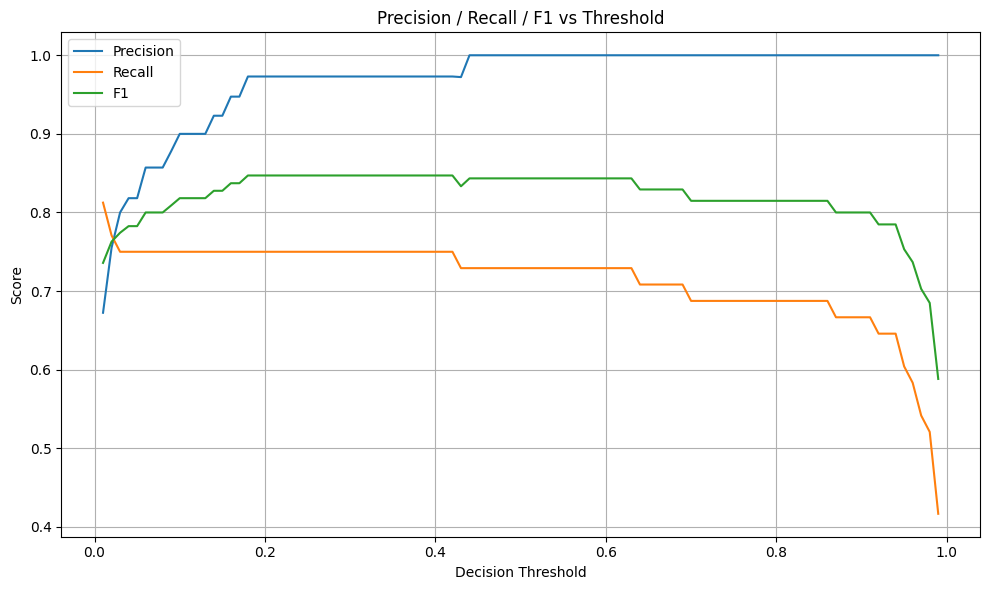

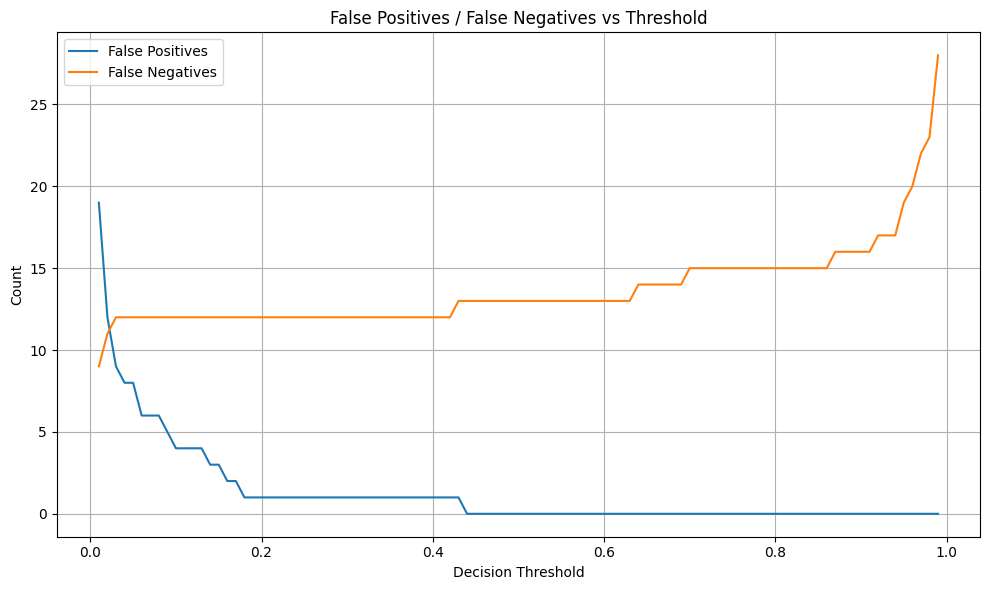


THRESHOLDS WITH PRECISION >= 95%


,Threshold,TP,FP,FN,Precision,Recall,F1
17,0.18,36,1,12,0.972973,0.750000,0.847059
18,0.19,36,1,12,0.972973,0.750000,0.847059
19,0.20,36,1,12,0.972973,0.750000,0.847059
20,0.21,36,1,12,0.972973,0.750000,0.847059
21,0.22,36,1,12,0.972973,0.750000,0.847059
...,...,...,...,...,...,...,...
94,0.95,29,0,19,1.000000,0.604167,0.753247
95,0.96,28,0,20,1.000000,0.583333,0.736842
96,0.97,26,0,22,1.000000,0.541667,0.702703
97,0.98,25,0,23,1.000000,0.520833,0.684932



THRESHOLDS WITH RECALL >= 80%


,Threshold,TP,FP,FN,Precision,Recall,F1
0,0.01,39,19,9,0.672414,0.8125,0.735849



Threshold analysis saved.


In [86]:
# ============================================================
# STAGE 7 — THRESHOLD OPTIMIZATION
# Credit Card Fraud Detection
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


# ------------------------------------------------------------
# 1. USE BEST CURRENT MODEL
# ------------------------------------------------------------

# Baseline XGBoost currently has the highest PR-AUC
best_model = xgb_baseline

# Generate validation probabilities
threshold_proba = best_model.predict_proba(X_val)[:, 1]

print("=" * 70)
print("STAGE 7 — THRESHOLD OPTIMIZATION")
print("=" * 70)

print(f"Validation samples : {len(y_val)}")
print(f"Actual frauds      : {y_val.sum()}")
print(f"Fraud rate         : {y_val.mean() * 100:.4f}%")


# ------------------------------------------------------------
# 2. TEST MANY THRESHOLDS
# ------------------------------------------------------------

thresholds = np.arange(
    0.01,
    1.00,
    0.01
)

threshold_results = []

for threshold in thresholds:

    y_pred = (
        threshold_proba >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred
    ).ravel()

    precision_t = precision_score(
        y_val,
        y_pred,
        zero_division=0
    )

    recall_t = recall_score(
        y_val,
        y_pred,
        zero_division=0
    )

    f1_t = f1_score(
        y_val,
        y_pred,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Precision": precision_t,
        "Recall": recall_t,
        "F1": f1_t
    })


threshold_df = pd.DataFrame(
    threshold_results
)


# ------------------------------------------------------------
# 3. BEST THRESHOLD BY F1
# ------------------------------------------------------------

best_f1_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

print("\n" + "=" * 70)
print("BEST THRESHOLD BY F1")
print("=" * 70)

print(
    best_f1_row.to_string()
)


# ------------------------------------------------------------
# 4. BEST THRESHOLD BY RECALL
#    SUBJECT TO PRECISION >= 90%
# ------------------------------------------------------------

precision_constraint = 0.90

eligible_recall = threshold_df[
    threshold_df["Precision"] >= precision_constraint
]

if len(eligible_recall) > 0:

    best_recall_row = eligible_recall.loc[
        eligible_recall["Recall"].idxmax()
    ]

    print("\n" + "=" * 70)
    print(
        f"BEST RECALL WITH PRECISION >= "
        f"{precision_constraint:.0%}"
    )
    print("=" * 70)

    print(
        best_recall_row.to_string()
    )

else:

    best_recall_row = None

    print(
        "\nNo threshold satisfies the "
        "precision constraint."
    )


# ------------------------------------------------------------
# 5. BEST THRESHOLD BY RECALL
#    SUBJECT TO PRECISION >= 95%
# ------------------------------------------------------------

precision_constraint_high = 0.95

eligible_high = threshold_df[
    threshold_df["Precision"] >= precision_constraint_high
]

if len(eligible_high) > 0:

    best_recall_high = eligible_high.loc[
        eligible_high["Recall"].idxmax()
    ]

    print("\n" + "=" * 70)
    print(
        f"BEST RECALL WITH PRECISION >= "
        f"{precision_constraint_high:.0%}"
    )
    print("=" * 70)

    print(
        best_recall_high.to_string()
    )

else:

    best_recall_high = None

    print(
        "\nNo threshold satisfies the "
        "high-precision constraint."
    )


# ------------------------------------------------------------
# 6. THRESHOLD = 0.50 REFERENCE
# ------------------------------------------------------------

default_row = threshold_df.iloc[
    np.argmin(
        np.abs(
            threshold_df["Threshold"] - 0.50
        )
    )
]

print("\n" + "=" * 70)
print("DEFAULT THRESHOLD = 0.50")
print("=" * 70)

print(
    default_row.to_string()
)


# ------------------------------------------------------------
# 7. DISPLAY IMPORTANT THRESHOLDS
# ------------------------------------------------------------

selected_thresholds = [
    0.01,
    0.05,
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
    0.80,
    0.90
]

threshold_table = threshold_df[
    threshold_df["Threshold"].round(2).isin(
        selected_thresholds
    )
].copy()

print("\n" + "=" * 70)
print("THRESHOLD TRADE-OFF TABLE")
print("=" * 70)

display(
    threshold_table[
        [
            "Threshold",
            "TP",
            "FP",
            "FN",
            "Precision",
            "Recall",
            "F1"
        ]
    ]
)


# ------------------------------------------------------------
# 8. PRECISION / RECALL / F1 CURVES
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision / Recall / F1 vs Threshold")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. FALSE POSITIVES / FALSE NEGATIVES
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["FP"],
    label="False Positives"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["FN"],
    label="False Negatives"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Count")
plt.title("False Positives / False Negatives vs Threshold")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. FIND ALL THRESHOLDS WITH HIGH PRECISION
# ------------------------------------------------------------

high_precision = threshold_df[
    threshold_df["Precision"] >= 0.95
]

print("\n" + "=" * 70)
print("THRESHOLDS WITH PRECISION >= 95%")
print("=" * 70)

if len(high_precision) > 0:

    display(
        high_precision[
            [
                "Threshold",
                "TP",
                "FP",
                "FN",
                "Precision",
                "Recall",
                "F1"
            ]
        ]
    )

else:

    print("None found.")


# ------------------------------------------------------------
# 11. FIND ALL THRESHOLDS WITH RECALL >= 80%
# ------------------------------------------------------------

high_recall = threshold_df[
    threshold_df["Recall"] >= 0.80
]

print("\n" + "=" * 70)
print("THRESHOLDS WITH RECALL >= 80%")
print("=" * 70)

if len(high_recall) > 0:

    display(
        high_recall[
            [
                "Threshold",
                "TP",
                "FP",
                "FN",
                "Precision",
                "Recall",
                "F1"
            ]
        ]
    )

else:

    print("No threshold reaches 80% recall.")


# ------------------------------------------------------------
# 12. SAVE THRESHOLD ANALYSIS
# ------------------------------------------------------------

threshold_df.to_csv(
    "threshold_analysis.csv",
    index=False
)

print("\nThreshold analysis saved.")

| Strategy       |     Threshold |  Precision |     Recall |        F1 |    FP |
| -------------- | ------------: | ---------: | ---------: | --------: | ----: |
| Aggressive     |          0.01 |     67.24% | **81.25%** |     0.736 |    19 |
| Balanced       |          0.10 |     90.00% |     75.00% |     0.818 |     4 |
| **F1-optimal** | **0.18–0.40** | **97.30%** | **75.00%** | **0.847** | **1** |
| Default        |          0.50 |       100% |     72.92% |     0.843 |     0 |
| Conservative   |          0.90 |       100% |     66.67% |     0.800 |     0 |
